In [26]:

import os

print(os.listdir('/content'))


['.config', 'attrition_by_Age.png', 'attrition_by_department.png', 'attrition_by_income.png', 'attrition_by_Satisfaction.png', 'attrition_by_overtime.png', '.ipynb_checkpoints', 'Employee_Attrition_Analysis.csv', 'sample_data']


In [27]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/Employee_Attrition_Analysis.csv')

# Display the first 5 rows
display(df.head())

# Check dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Rows: 1470
Columns: 35


In [28]:

# Dataset information
df.info()

# Missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Employee attrition distribution
print("\nAttrition distribution:")
print(df["Attrition"].value_counts())

# Summary statistics
display(df.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [29]:

# 1. Check missing values in each column
missing = df.isnull().sum()
print("Columns with missing values:")
print(missing[missing > 0])

# 2. Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Check unique values in important columns
for col in ["Attrition", "Department", "OverTime", "Gender", "JobRole"]:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts(dropna=False))

# 4. Check columns with only one unique value
constant_cols = [
    col for col in df.columns if df[col].nunique(dropna=False) == 1
]
print("\nColumns with only one unique value:", constant_cols)

# 5. Check exact column names
print("\nColumn names:")
print(df.columns.tolist())


Columns with missing values:
Series([], dtype: int64)

Duplicate rows: 0

Attrition:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Department:
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

OverTime:
OverTime
No     1054
Yes     416
Name: count, dtype: int64

Gender:
Gender
Male      882
Female    588
Name: count, dtype: int64

JobRole:
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

Columns with only one unique value: ['EmployeeCount', 'Over18', 'StandardHours']

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'Em

In [30]:

# Work on a copy so the original dataset stays unchanged
df_clean = df.copy()

# Remove constant columns, if present
constant_cols = [
    col for col in df_clean.columns
    if df_clean[col].nunique(dropna=False) == 1
]

df_clean = df_clean.drop(columns=constant_cols)

print("Removed columns:", constant_cols)
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)


Removed columns: ['EmployeeCount', 'Over18', 'StandardHours']
Original shape: (1470, 35)
Cleaned shape: (1470, 32)


In [31]:

# Total employees
total_employees = len(df_clean)

# Employees who left
employees_left = (df_clean["Attrition"] == "Yes").sum()

# Employees who stayed
employees_stayed = (df_clean["Attrition"] == "No").sum()

# Attrition rate
attrition_rate = (employees_left / total_employees) * 100

print("========== HR ATTRITION KPIs ==========")
print(f"Total Employees: {total_employees}")
print(f"Employees Who Left: {employees_left}")
print(f"Employees Who Stayed: {employees_stayed}")
print(f"Attrition Rate: {attrition_rate:.2f}%")


========== HR ATTRITION KPIs ==========
Total Employees: 1470
Employees Who Left: 237
Employees Who Stayed: 1233
Attrition Rate: 16.12%


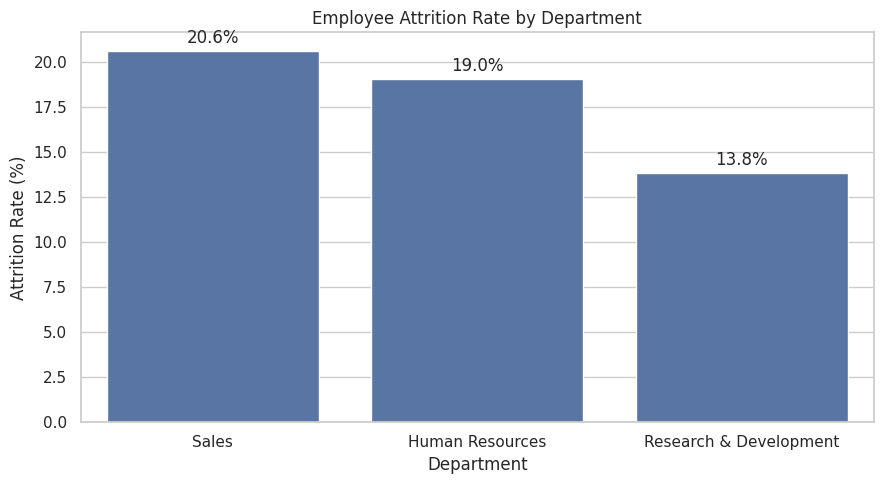

In [32]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

department_attrition = (
    df_clean.groupby("Department")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=department_attrition.index,
    y=department_attrition.values
)

plt.title("Employee Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig(
    "attrition_by_department.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


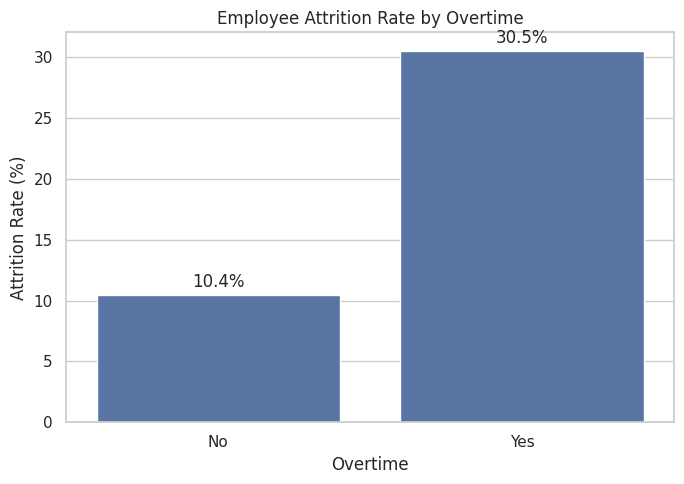

In [33]:

overtime_attrition = (
    df_clean.groupby("OverTime")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=overtime_attrition.index,
    y=overtime_attrition.values
)

plt.title("Employee Attrition Rate by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig(
    "attrition_by_overtime.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


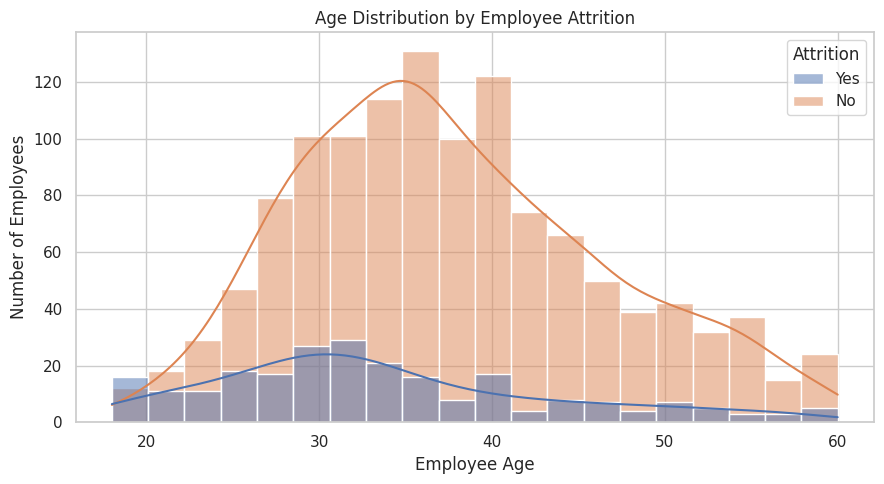

In [34]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="Age",
    hue="Attrition",
    bins=20,
    multiple="layer",
    kde=True
)

plt.title("Age Distribution by Employee Attrition")
plt.xlabel("Employee Age")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.savefig(
    "attrition_by_Age.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


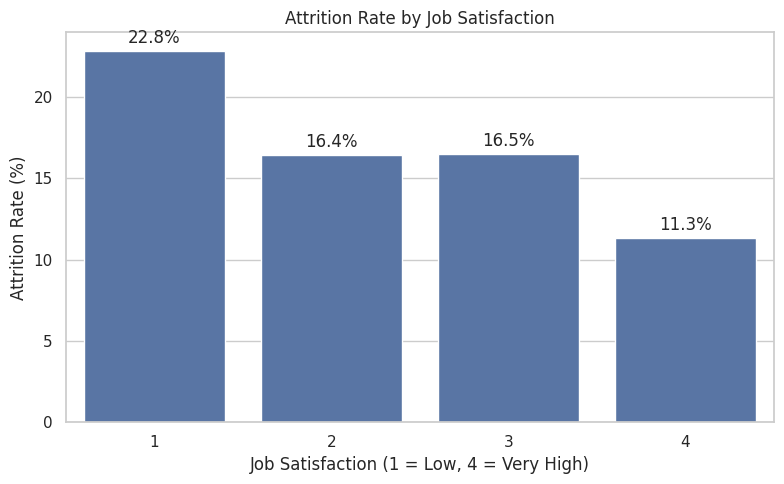

In [35]:

satisfaction_attrition = (
    df_clean.groupby("JobSatisfaction")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=satisfaction_attrition.index,
    y=satisfaction_attrition.values
)

plt.title("Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction (1 = Low, 4 = Very High)")
plt.ylabel("Attrition Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig(
    "attrition_by_Satisfaction.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

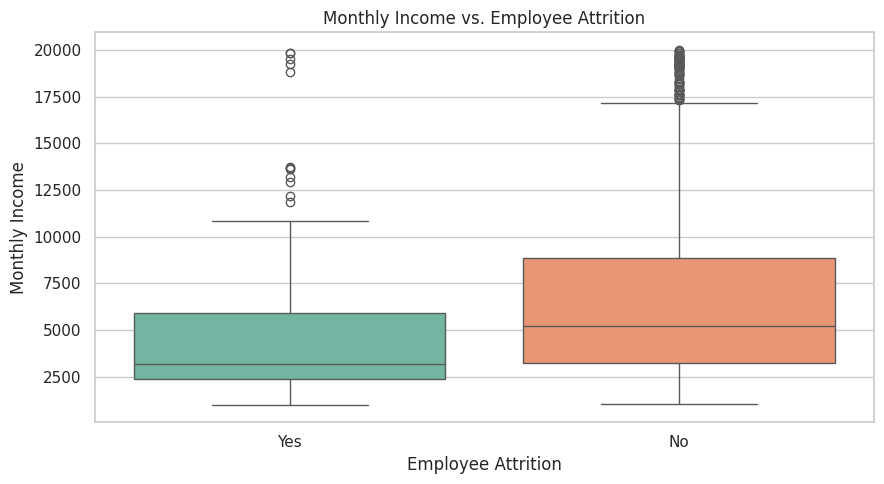

In [36]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="MonthlyIncome",
    hue="Attrition",
    palette="Set2",
    legend=False
)

plt.title("Monthly Income vs. Employee Attrition")
plt.xlabel("Employee Attrition")
plt.ylabel("Monthly Income")
plt.tight_layout()

plt.savefig(
    "attrition_by_income.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [37]:

# Step 5: Create employee groups
df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"]
)

df_clean["IncomeGroup"] = pd.cut(
    df_clean["MonthlyIncome"],
    bins=[0, 3000, 6000, 10000, float("inf")],
    labels=["Below 3000", "3000-6000", "6001-10000", "Above 10000"]
)

# Function to calculate attrition
def attrition_summary(column):
    result = df_clean.groupby(column, observed=False).agg(
        Total_Employees=("Attrition", "size"),
        Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
    )

    result["Attrition_Rate_%"] = (
        result["Employees_Left"] / result["Total_Employees"] * 100
    ).round(2)

    return result.sort_values("Attrition_Rate_%", ascending=False)

# Display summary tables
for column in [
    "AgeGroup",
    "IncomeGroup",
    "YearsAtCompany",
    "JobSatisfaction",
    "OverTime",
    "Department"
]:
    print(f"\n{'=' * 12} {column} {'=' * 12}")
    display(attrition_summary(column))



============ AgeGroup ============


,Total_Employees,Employees_Left,Attrition_Rate_%
AgeGroup,,,
18-25,123,44,35.77
26-35,606,116,19.14
56-65,47,8,17.02
46-55,226,26,11.50
36-45,468,43,9.19



============ IncomeGroup ============


,Total_Employees,Employees_Left,Attrition_Rate_%
IncomeGroup,,,
Below 3000,395,113,28.61
3000-6000,519,66,12.72
6001-10000,275,33,12.00
Above 10000,281,25,8.90



============ YearsAtCompany ============


...

,Total_Employees,Employees_Left,Attrition_Rate_%
JobSatisfaction,,,
1,289,66,22.84
3,442,73,16.52
2,280,46,16.43
4,459,52,11.33



============ OverTime ============


,Total_Employees,Employees_Left,Attrition_Rate_%
OverTime,,,
Yes,416,127,30.53
No,1054,110,10.44



============ Department ============


,Total_Employees,Employees_Left,Attrition_Rate_%
Department,,,
Sales,446,92,20.63
Human Resources,63,12,19.05
Research & Development,961,133,13.84


In [38]:

import pandas as pd
from google.colab import files

summary_columns = [
    "AgeGroup",
    "IncomeGroup",
    "YearsAtCompany",
    "JobSatisfaction",
    "OverTime",
    "Department"
]

summary_results = []

for column in summary_columns:
    result = attrition_summary(column).reset_index()
    result.insert(0, "Analysis_Category", column)
    summary_results.append(result)

final_summary = pd.concat(summary_results, ignore_index=True)

final_summary.to_csv(
    "Employee_Attrition_Summary.csv",
    index=False
)

files.download("Employee_Attrition_Summary.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:

# Step 6: Prepare data for machine learning

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Separate features and target
X = df_clean.drop(columns=["Attrition", "EmployeeNumber"], errors="ignore")
y = df_clean["Attrition"].map({"No": 0, "Yes": 1})

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_cols = X.select_dtypes(include=["number"]).columns.tolist()

# Preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))
print("Data preparation completed successfully!")


Training rows: 1176
Testing rows: 294
Numerical features: 23
Categorical features: 9
Data preparation completed successfully!


In [40]:

# Step 7: Train and evaluate both models

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_test, y_pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_test, y_pred, zero_division=0) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, y_pred, zero_division=0) * 100, 2)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)
display(results_df)


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Logistic Regression,75.85,36.05,65.96,46.62
1,Random Forest,84.35,57.14,8.51,14.81



Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.92      0.78      0.84       247
        Left       0.36      0.66      0.47        47

    accuracy                           0.76       294
   macro avg       0.64      0.72      0.66       294
weighted avg       0.83      0.76      0.78       294



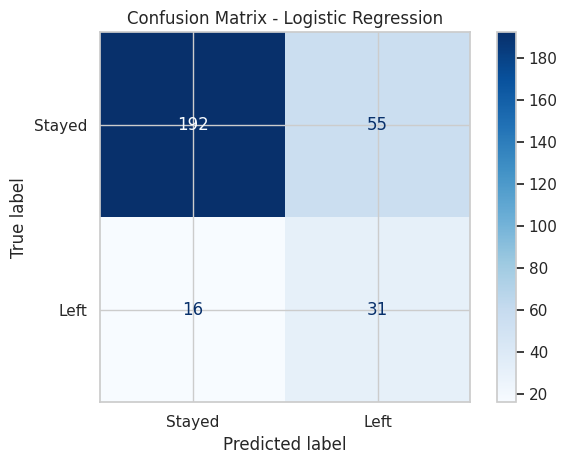


Random Forest
              precision    recall  f1-score   support

      Stayed       0.85      0.99      0.91       247
        Left       0.57      0.09      0.15        47

    accuracy                           0.84       294
   macro avg       0.71      0.54      0.53       294
weighted avg       0.81      0.84      0.79       294



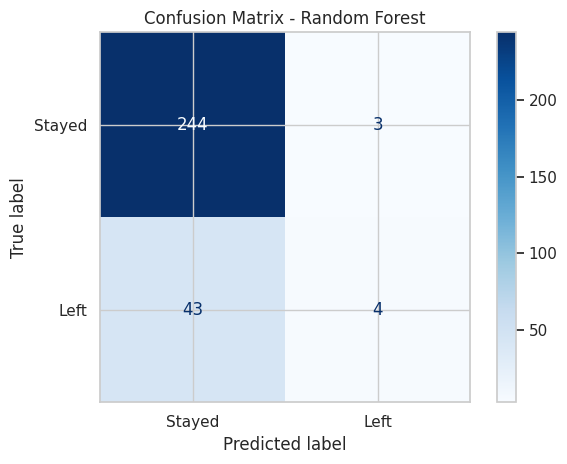

In [41]:

from sklearn.metrics import ConfusionMatrixDisplay, classification_report

for name, model in trained_models.items():
    print(f"\n{name}")

    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Stayed", "Left"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["Stayed", "Left"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()


In [42]:

results_df.to_csv("Employee_Attrition_Model_Comparison.csv", index=False)

from google.colab import files
files.download("Employee_Attrition_Model_Comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)
import pandas as pd

rf_model = trained_models["Random Forest"]

# Probability that each test employee belongs to the "Left" class
left_probabilities = rf_model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
    predictions = (left_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy (%)": round(accuracy_score(y_test, predictions) * 100, 2),
        "Precision_Left (%)": round(
            precision_score(y_test, predictions, zero_division=0) * 100, 2
        ),
        "Recall_Left (%)": round(
            recall_score(y_test, predictions, zero_division=0) * 100, 2
        ),
        "F1_Left (%)": round(
            f1_score(y_test, predictions, zero_division=0) * 100, 2
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)


,Threshold,Accuracy (%),Precision_Left (%),Recall_Left (%),F1_Left (%)
0,0.15,71.77,33.33,76.60,46.45
1,0.20,79.59,40.85,61.70,49.15
2,0.25,82.31,45.28,51.06,48.00
3,0.30,82.99,46.34,40.43,43.18
4,0.35,83.67,48.00,25.53,33.33
5,0.40,83.67,47.06,17.02,25.00
6,0.50,84.35,57.14,8.51,14.81


In [44]:

# Save Random Forest threshold analysis
threshold_df.to_csv(
    "Random_Forest_Threshold_Analysis.csv",
    index=False
)

from google.colab import files
files.download("Random_Forest_Threshold_Analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:

# Final Business Insights

total_employees = len(df_clean)
employees_left = (df_clean["Attrition"] == "Yes").sum()
overall_attrition = employees_left / total_employees * 100

print("========== EMPLOYEE ATTRITION INSIGHTS ==========")
print(f"Total employees analyzed: {total_employees}")
print(f"Employees who left: {employees_left}")
print(f"Overall attrition rate: {overall_attrition:.2f}%")

# Department with highest attrition rate
department_rates = (
    df_clean.groupby("Department")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
print(f"\nHighest department attrition: {department_rates.index[0]}")
print(f"Department attrition rate: {department_rates.iloc[0]:.2f}%")

# Attrition by overtime
overtime_rates = (
    df_clean.groupby("OverTime")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)
print("\nAttrition by overtime:")
display(overtime_rates.round(2).rename("Attrition_Rate_%").to_frame())

# Attrition by job satisfaction
satisfaction_rates = (
    df_clean.groupby("JobSatisfaction")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)
print("\nAttrition by job satisfaction:")
display(satisfaction_rates.round(2).rename("Attrition_Rate_%").to_frame())

# Attrition by income group
income_rates = (
    df_clean.groupby("IncomeGroup", observed=False)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)
print("\nAttrition by income group:")
display(income_rates.round(2).rename("Attrition_Rate_%").to_frame())


========== EMPLOYEE ATTRITION INSIGHTS ==========
Total employees analyzed: 1470
Employees who left: 237
Overall attrition rate: 16.12%

Highest department attrition: Sales
Department attrition rate: 20.63%

Attrition by overtime:


,Attrition_Rate_%
OverTime,
No,10.44
Yes,30.53



Attrition by job satisfaction:


,Attrition_Rate_%
JobSatisfaction,
1,22.84
2,16.43
3,16.52
4,11.33



Attrition by income group:


,Attrition_Rate_%
IncomeGroup,
Below 3000,28.61
3000-6000,12.72
6001-10000,12.00
Above 10000,8.90
